In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              roc_curve, roc_auc_score, precision_recall_curve, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# EDA


In [2]:
df = pd.read_csv("./avocado_ripeness_dataset.csv")
df.columns = ["firmness", "hue", "saturation", 
              "brightness", "color_category", 
              "sound_db", "weight_g",
              "size_cm3", "ripeness"
              ]


In [3]:
print(df.shape)
df.head()

(250, 9)


,firmness,hue,saturation,brightness,color_category,sound_db,weight_g,size_cm3,ripeness
0,14.5,19,40,26,black,34,175,261,ripe
1,71.7,53,69,75,green,69,206,185,pre-conditioned
2,88.5,60,94,46,dark green,79,220,143,hard
3,93.8,105,87,41,dark green,75,299,140,hard
4,42.5,303,58,32,purple,63,200,227,breaking


In [4]:
df = df.drop_duplicates()
df = df.dropna()
print(df.shape)

(250, 9)


In [5]:
numerical_features = ["firmness", "hue", "saturation", 
              "brightness","sound_db", "weight_g",
              "size_cm3"]

categorical_features = ["color_category"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)


In [6]:

print(df_encoded.shape)

(250, 11)


In [7]:
df_encoded.head()

,firmness,hue,saturation,brightness,sound_db,weight_g,size_cm3,ripeness,color_category_dark green,color_category_green,color_category_purple
0,14.5,19,40,26,34,175,261,ripe,0,0,0
1,71.7,53,69,75,69,206,185,pre-conditioned,0,1,0
2,88.5,60,94,46,79,220,143,hard,1,0,0
3,93.8,105,87,41,75,299,140,hard,1,0,0
4,42.5,303,58,32,63,200,227,breaking,0,0,1


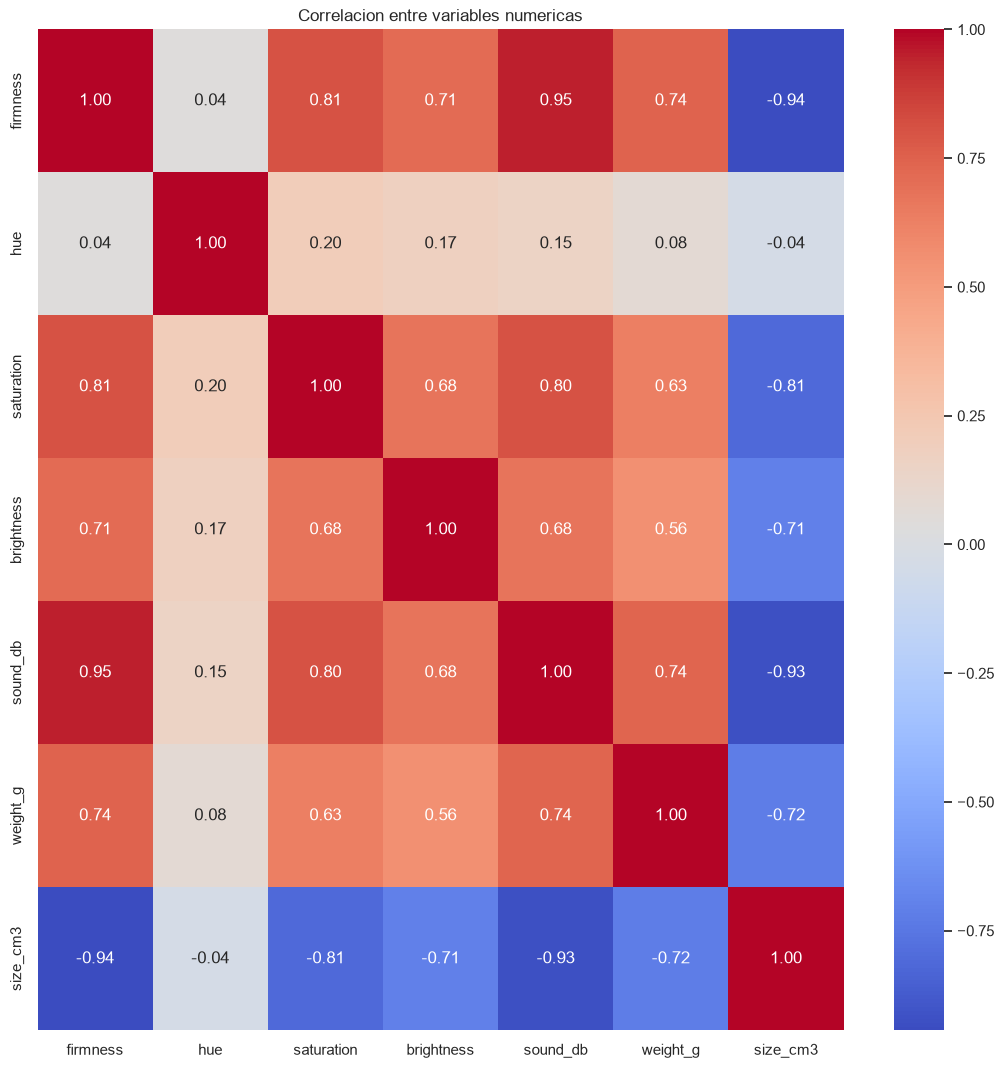

In [8]:
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

# MATRIZ DE DISEÑO

In [9]:

X = df_encoded.drop(columns=["ripeness"])
y = df_encoded["ripeness"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.30,random_state=42,stratify=y
)

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# KNN

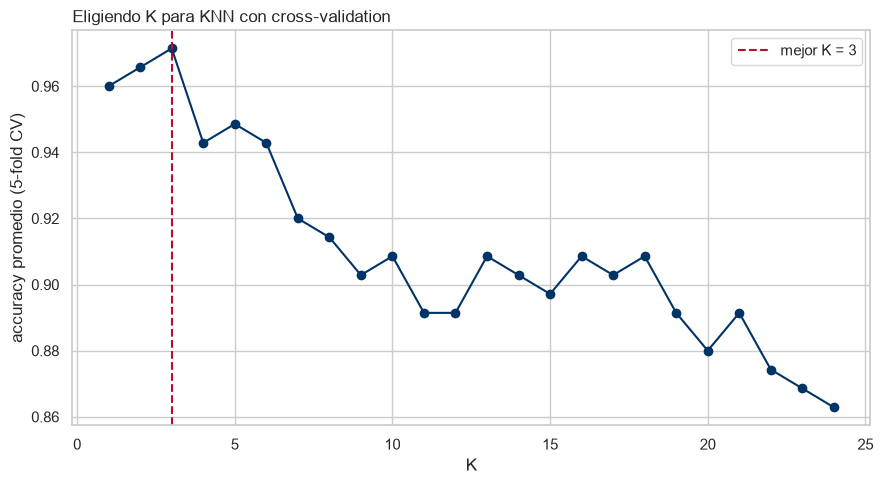

In [10]:
k_grid = range(1, 25)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train, y_train)
y_pred_knn = KNN_model.predict(X_test)

In [12]:
print(accuracy_score(y_test, y_pred_knn))

0.92


In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

baseline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    DummyClassifier(strategy="most_frequent")
)

scores = cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Baseline promedio:", scores.mean())
print("Desviación estándar:", scores.std())

Baseline promedio: 0.2
Desviación estándar: 0.0


# Árbol

In [14]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_scores = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores))]
print(f"Mejor alpha por CV: {best_alpha:.4f}")

model_dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
model_dt_pruned.fit(X_train, y_train)

y_pred_dt = model_dt_pruned.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_dt, zero_division=0))

Mejor alpha por CV: 0.0000

Accuracy: 1.0

Reporte de Clasificación:
                  precision    recall  f1-score   support

       breaking       1.00      1.00      1.00        15
      firm-ripe       1.00      1.00      1.00        15
           hard       1.00      1.00      1.00        15
pre-conditioned       1.00      1.00      1.00        15
           ripe       1.00      1.00      1.00        15

       accuracy                           1.00        75
      macro avg       1.00      1.00      1.00        75
   weighted avg       1.00      1.00      1.00        75



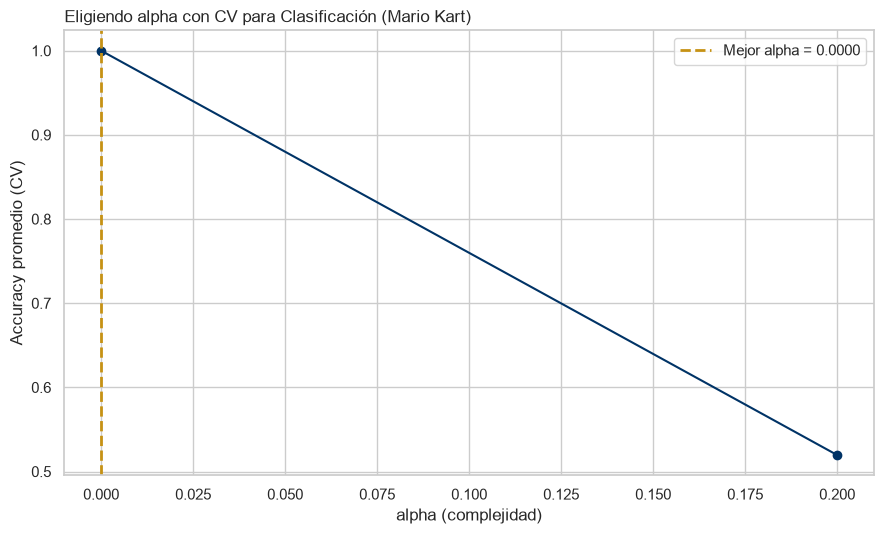

In [15]:
plt.figure(figsize=(9, 5.5))
plt.plot(ccp_alphas, cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_alpha, color=UP_GOLD, ls="--", lw=2, label=f"Mejor alpha = {best_alpha:.4f}")
plt.xlabel("alpha (complejidad)")
plt.ylabel("Accuracy promedio (CV)")
plt.title("Eligiendo alpha con CV para Clasificación (Mario Kart)", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
arbol_sin_podar = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

comparacion = pd.DataFrame({
    "modelo": ["Sin podar", "Podado (CV)"],
    "n_hojas": [arbol_sin_podar.get_n_leaves(), arbol_podado.get_n_leaves()],
    "accuracy_test": [
        accuracy_score(y_test, arbol_sin_podar.predict(X_test)),
        accuracy_score(y_test, arbol_podado.predict(X_test)),
    ],
}).round(3)
comparacion

,modelo,n_hojas,accuracy_test
0,Sin podar,5,1.0
1,Podado (CV),5,1.0


# Observaciones

Pocos datos para muchas clases, no se puede entrenar bien el modelo y por eso nos arroja un accuracy muy bajo. Tampoco se pueden podar los árboles, ya que al intentar simplificar el arbol, solo logra que el accuracy del test baje.